In [ ]:
!pip install --upgrade numpy
!pip install --upgrade pandas
!pip install --upgrade --force-reinstall numpy
!pip install --upgrade --force-reinstall pandas
!pip install --upgrade scikit-learn

  Using cached numpy-2.5.5-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
Using cached numpy-2.5.5-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (15.7 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.5
    Uninstalling numpy-2.5.5:
      Successfully uninstalled numpy-2.5.5
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.5 which is incompatible.


  Using cached pandas-3.1.1-cp313-cp313-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (16 kB)
  Using cached numpy-2.5.5-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
  Using cached python_dateutil-4.0.0-py3-none-any.whl.metadata (7.3 kB)
  Using cached tzdata-2026.6-py2.py3-none-any.whl.metadata (1.4 kB)
Using cached pandas-3.1.1-cp313-cp313-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl (12.0 MB)
Using cached numpy-2.5.5-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (15.7 MB)
Using cached python_dateutil-4.0.0-py3-none-any.whl (92 kB)
Using cached tzdata-2026.6-py2.py3-none-any.whl (348 kB)
ERROR: Operation cancelled by user
^C


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, StackingClassifier,VotingClassifier
from xgboost import XGBClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, classification_report
import warnings
from sklearn.linear_model import LogisticRegression
import numpy as np

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [2]:
warnings.filterwarnings("ignore", category=UserWarning)



In [3]:

# Load dataset
file_path = "dementia_dataset.csv"
df = pd.read_csv(file_path)

In [4]:
# Drop unnecessary columns
df_cleaned = df.drop(columns=["Subject ID", "MRI ID"])

In [5]:
# Handle missing values
imputer_ses = SimpleImputer(strategy="median")
imputer_mmse = SimpleImputer(strategy="mean")
df_cleaned["SES"] = imputer_ses.fit_transform(df_cleaned[["SES"]])
df_cleaned["MMSE"] = imputer_mmse.fit_transform(df_cleaned[["MMSE"]])

In [6]:
# Encode categorical variables
label_encoders = {}
for col in ["M/F","Hand","Group"]:
    le = LabelEncoder()
    df_cleaned[col] = le.fit_transform(df_cleaned[col])
    label_encoders[col] = le


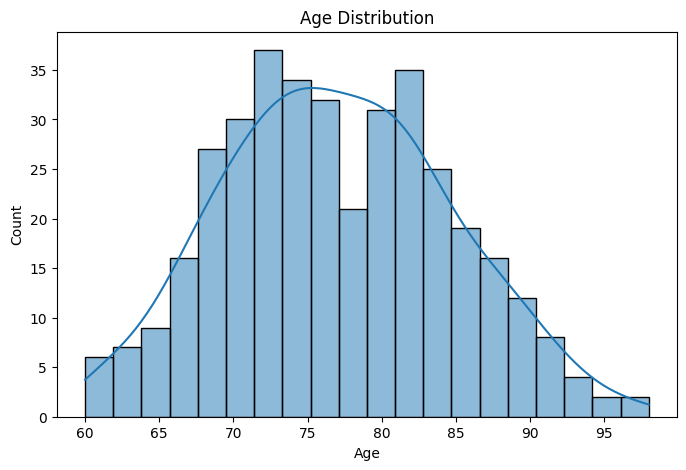

In [7]:
# Data Visualizations
plt.figure(figsize=(8, 5))
sns.histplot(df_cleaned["Age"], bins=20, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

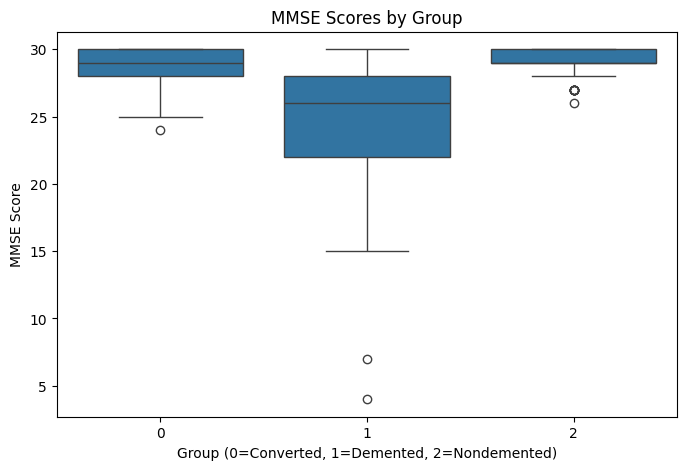

In [8]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=df_cleaned["Group"], y=df_cleaned["MMSE"])
plt.title("MMSE Scores by Group")
plt.xlabel("Group (0=Converted, 1=Demented, 2=Nondemented)")
plt.ylabel("MMSE Score")
plt.show()

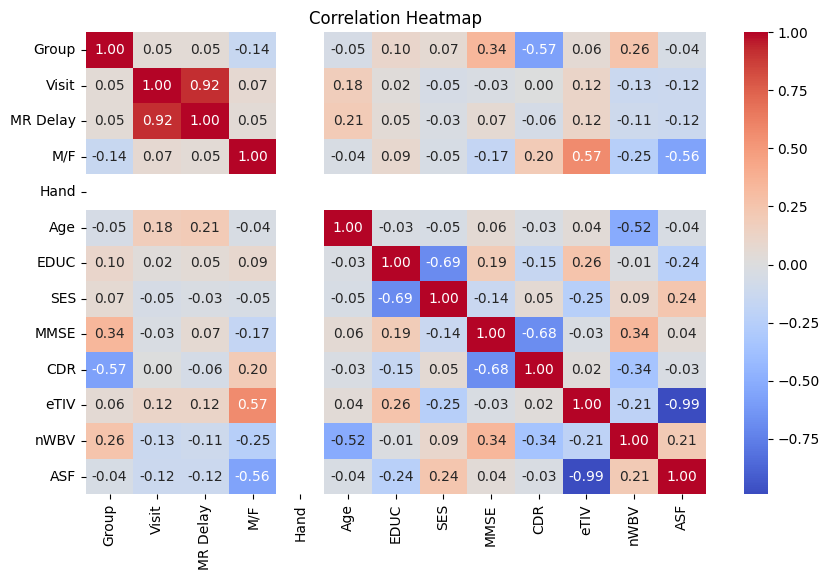

In [9]:
plt.figure(figsize=(10, 6))
sns.heatmap(df_cleaned.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

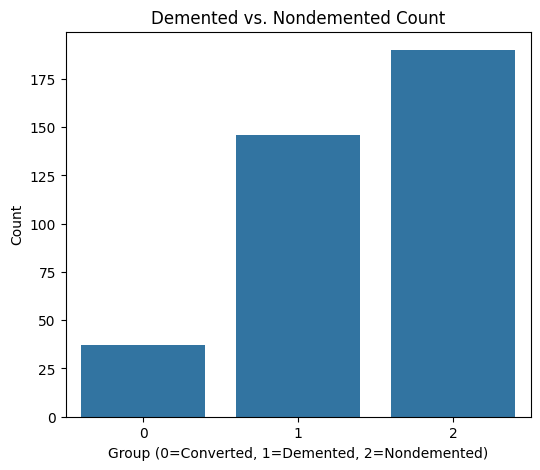

In [10]:
plt.figure(figsize=(6, 5))
sns.countplot(x=df_cleaned["Group"])
plt.title("Demented vs. Nondemented Count")
plt.xlabel("Group (0=Converted, 1=Demented, 2=Nondemented)")
plt.ylabel("Count")
plt.show()

In [11]:
# Split dataset into features and target variable
X = df_cleaned.drop(columns=["Group"])
y = df_cleaned["Group"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


In [12]:
# Random Forest Model
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [13]:
y_pred_rf = rf.predict(X_test)
print("Random Forest Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.2f}")
print(f"Precision: {precision_score(y_test, y_pred_rf, average='weighted'):.2f}")
print(f"Recall: {recall_score(y_test, y_pred_rf, average='weighted'):.2f}")
print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred_rf)}")
print(f"Classification Report:\n{classification_report(y_test, y_pred_rf)}")
print("-" * 50)

Random Forest Results:
Accuracy: 0.92
Precision: 0.93
Recall: 0.92
Confusion Matrix:
[[ 2  1  5]
 [ 0 29  0]
 [ 0  0 38]]
Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.25      0.40         8
           1       0.97      1.00      0.98        29
           2       0.88      1.00      0.94        38

    accuracy                           0.92        75
   macro avg       0.95      0.75      0.77        75
weighted avg       0.93      0.92      0.90        75

--------------------------------------------------


In [14]:
# XGBoost Model
xgb = XGBClassifier(use_label_encoder=False, eval_metric="mlogloss", random_state=42)
xgb.fit(X_train, y_train)

,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklear

In [15]:
y_pred_xgb = xgb.predict(X_test)
print("XGBoost Results:")
print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb, average='weighted'))
print("Recall:", recall_score(y_test, y_pred_xgb, average='weighted'))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_xgb))
print("Classification Report:\n", classification_report(y_test, y_pred_xgb))
print("-" * 50)

XGBoost Results:
Accuracy: 0.8933333333333333
Precision: 0.8739424141749723
Recall: 0.8933333333333333
Confusion Matrix:
 [[ 2  1  5]
 [ 2 27  0]
 [ 0  0 38]]
Classification Report:
               precision    recall  f1-score   support

           0       0.50      0.25      0.33         8
           1       0.96      0.93      0.95        29
           2       0.88      1.00      0.94        38

    accuracy                           0.89        75
   macro avg       0.78      0.73      0.74        75
weighted avg       0.87      0.89      0.88        75

--------------------------------------------------


In [16]:
# Gradient Boosting Model
gb = GradientBoostingClassifier(n_estimators=200, random_state=42)
gb.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",200
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [17]:
y_pred_gb = gb.predict(X_test)
print("Gradient Boosting Results:")
print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb, average='weighted'))
print("Recall:", recall_score(y_test, y_pred_gb, average='weighted'))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_gb))
print("Classification Report:\n", classification_report(y_test, y_pred_gb))
print("-" * 50)

Gradient Boosting Results:
Accuracy: 0.92
Precision: 0.9117460317460317
Recall: 0.92
Confusion Matrix:
 [[ 3  1  4]
 [ 1 28  0]
 [ 0  0 38]]
Classification Report:
               precision    recall  f1-score   support

           0       0.75      0.38      0.50         8
           1       0.97      0.97      0.97        29
           2       0.90      1.00      0.95        38

    accuracy                           0.92        75
   macro avg       0.87      0.78      0.81        75
weighted avg       0.91      0.92      0.91        75

--------------------------------------------------


In [18]:
# Stacking Classifier
stacking_clf = StackingClassifier(estimators=[
    ('Random Forest', RandomForestClassifier(n_estimators=200, random_state=42)),
    ('XGBoost', XGBClassifier(eval_metric="mlogloss", use_label_encoder=False, random_state=42)),
    ('Gradient Boosting', GradientBoostingClassifier(n_estimators=200, random_state=42))
], final_estimator=LogisticRegression(), passthrough=True)
stacking_clf.fit(X_train, y_train)


,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.The type of estimator is generally expected to be a classifier.However, one can pass a regressor for some use case (e.g. ordinalregression).","[('Random Forest', ...), ('XGBoost', ...), ...]"
,"final_estimator final_estimator: estimator, default=NoneA classifier which will be used to combine the base estimators.The default classifier is a:class:`~sklearn.linear_model.LogisticRegression`.",LogisticRegression()
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",True
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",None
,"stack_method stack_method: {'auto', 'predict_proba', 'decision_function', 'predict'}, default='auto'Methods called for each base estimator. It can be:* if 'auto', it will try to invoke, for each estimator, `'predict_proba'`, `'decision_function'` or `'predict'` in that order.* otherwise, one of `'predict_proba'`, `'decision_function'` or `'predict'`. If the method is not implemented by the estimator, it will raise an error.",'auto'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Verbosity level.",0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,) or list of ndarray if `y` is of type `""multilabel-indicator""`.Class labels.","ndarray[int64](3,)","[0,1,2]"
"estimators_ estimators_: list of estimatorsThe elements of the `estimators` parameter, having been fitted on thetraining data. If an estimator has been set to `'drop'`, itwill not appear in `estimators_`. When `cv=""prefit""`, `estimators_`is set to `estimators` and is not fitted again.",list,"[RandomForestC...ndom_state=42), XGBClassifier...ree=None, ...), GradientBoost...ndom_state=42)]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... ve

In [19]:
y_pred_stacking = stacking_clf.predict(X_test)
print("Stacking Classifier Results:")
print("Accuracy:", accuracy_score(y_test, y_pred_stacking))
print("Precision:", precision_score(y_test, y_pred_stacking, average='weighted'))
print("Recall:", recall_score(y_test, y_pred_stacking, average='weighted'))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_stacking))
print("Classification Report:\n", classification_report(y_test, y_pred_stacking))
print("-" * 50)

Stacking Classifier Results:
Accuracy: 0.8666666666666667
Precision: 0.8307301587301588
Recall: 0.8666666666666667
Confusion Matrix:
 [[ 1  2  5]
 [ 0 28  1]
 [ 2  0 36]]
Classification Report:
               precision    recall  f1-score   support

           0       0.33      0.12      0.18         8
           1       0.93      0.97      0.95        29
           2       0.86      0.95      0.90        38

    accuracy                           0.87        75
   macro avg       0.71      0.68      0.68        75
weighted avg       0.83      0.87      0.84        75

--------------------------------------------------


In [20]:
# Blending Technique
rf_preds = rf.predict_proba(X_test)
xgb_preds = xgb.predict_proba(X_test)
gb_preds = gb.predict_proba(X_test)
blended_preds = (rf_preds + xgb_preds + gb_preds) / 3
blended_preds_final = np.argmax(blended_preds, axis=1)

In [21]:
print("Blending Technique Results:")
print("Accuracy:", accuracy_score(y_test, blended_preds_final))
print("Precision:", precision_score(y_test, blended_preds_final, average='weighted'))
print("Recall:", recall_score(y_test, blended_preds_final, average='weighted'))
print("Confusion Matrix:\n", confusion_matrix(y_test, blended_preds_final))
print("Classification Report:\n", classification_report(y_test, blended_preds_final))
print("-" * 50)

Blending Technique Results:
Accuracy: 0.8933333333333333
Precision: 0.8739424141749723
Recall: 0.8933333333333333
Confusion Matrix:
 [[ 2  1  5]
 [ 2 27  0]
 [ 0  0 38]]
Classification Report:
               precision    recall  f1-score   support

           0       0.50      0.25      0.33         8
           1       0.96      0.93      0.95        29
           2       0.88      1.00      0.94        38

    accuracy                           0.89        75
   macro avg       0.78      0.73      0.74        75
weighted avg       0.87      0.89      0.88        75

--------------------------------------------------


In [22]:
#Voting Classifier
voting_clf = VotingClassifier(estimators=[
    ('Random Forest', RandomForestClassifier(n_estimators=200, random_state=42)),
    ('XGBoost', XGBClassifier(eval_metric="mlogloss", use_label_encoder=False, random_state=42)),
    ('Gradient Boosting', GradientBoostingClassifier(n_estimators=200, random_state=42))
], voting='hard')
voting_clf.fit(X_train, y_train)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('Random Forest', ...), ('XGBoost', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'hard'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](3,)","[0,1,2]"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[RandomForestC...ndom_state=42), XGBClassifier...ree=None, ...), GradientBoost...ndom_state=42)]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['Visit','MR Delay','M/F',...,'eTIV','nWBV','ASF']"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()


In [23]:
y_pred_voting = voting_clf.predict(X_test)
print("Voting Classifier Results:")
print("Accuracy:", accuracy_score(y_test, y_pred_voting))
print("Precision:", precision_score(y_test, y_pred_voting, average='weighted'))
print("Recall:", recall_score(y_test, y_pred_voting, average='weighted'))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_voting))
print("Classification Report:\n", classification_report(y_test, y_pred_voting))
print("-" * 50)

Voting Classifier Results:
Accuracy: 0.9066666666666666
Precision: 0.8921963824289406
Recall: 0.9066666666666666
Confusion Matrix:
 [[ 2  1  5]
 [ 1 28  0]
 [ 0  0 38]]
Classification Report:
               precision    recall  f1-score   support

           0       0.67      0.25      0.36         8
           1       0.97      0.97      0.97        29
           2       0.88      1.00      0.94        38

    accuracy                           0.91        75
   macro avg       0.84      0.74      0.76        75
weighted avg       0.89      0.91      0.89        75

--------------------------------------------------


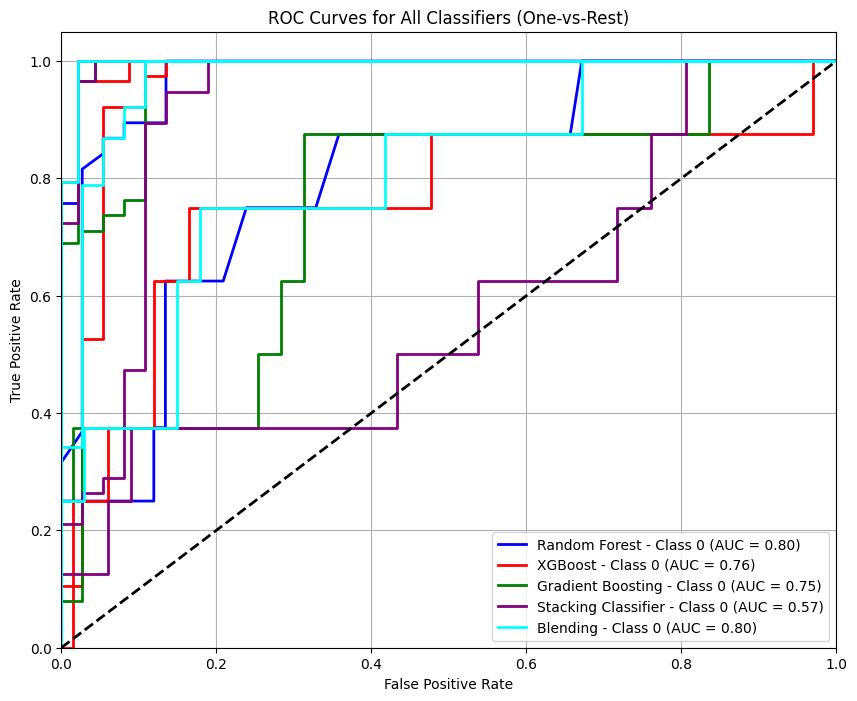

In [24]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from itertools import cycle


n_classes = 3
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

classifiers = {
    "Random Forest": rf,
    "XGBoost": xgb,
    "Gradient Boosting": gb,
    "Stacking Classifier": stacking_clf,
    "Voting Classifier": voting_clf
}

blended_preds = blended_preds  # From your blending technique

plt.figure(figsize=(10, 8))
colors = cycle(['blue', 'red', 'green', 'purple', 'orange', 'cyan'])
lw = 2  # Line width

for (name, clf), color in zip(classifiers.items(), colors):
    if name == "Voting Classifier":  # VotingClassifier with 'hard' voting doesn’t support predict_proba
        continue
    y_score = clf.predict_proba(X_test)
    for i in range(n_classes):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, color=color, lw=lw,
                 label=f'{name} - Class {i} (AUC = {roc_auc:.2f})' if i == 0 else None)

for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], blended_preds[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color='cyan', lw=lw,
             label=f'Blending - Class {i} (AUC = {roc_auc:.2f})' if i == 0 else None)

# Plot settings
plt.plot([0, 1], [0, 1], 'k--', lw=lw)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves for All Classifiers (One-vs-Rest)')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

/tmp/ipykernel_3646/1104015137.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(accuracies.keys()), y=list(accuracies.values()), palette="viridis")


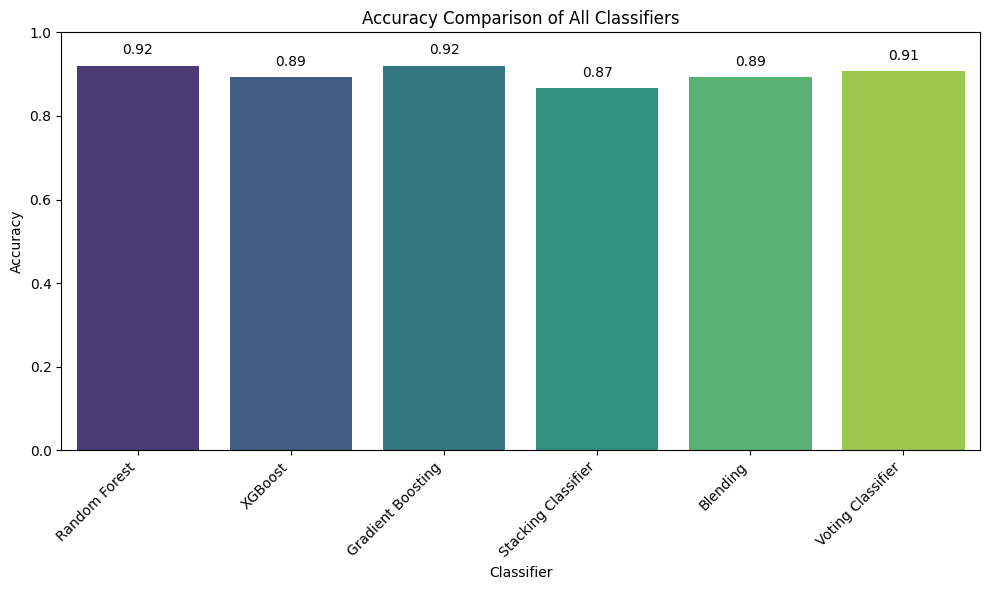

In [25]:
accuracies = {
    "Random Forest": accuracy_score(y_test, y_pred_rf),
    "XGBoost": accuracy_score(y_test, y_pred_xgb),
    "Gradient Boosting": accuracy_score(y_test, y_pred_gb),
    "Stacking Classifier": accuracy_score(y_test, y_pred_stacking),
    "Blending": accuracy_score(y_test, blended_preds_final),
    "Voting Classifier": accuracy_score(y_test, y_pred_voting)
}


plt.figure(figsize=(10, 6))
sns.barplot(x=list(accuracies.keys()), y=list(accuracies.values()), palette="viridis")
plt.title("Accuracy Comparison of All Classifiers")
plt.xlabel("Classifier")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha='right')


for i, v in enumerate(accuracies.values()):
    plt.text(i, v + 0.02, f"{v:.2f}", ha='center', va='bottom')

plt.tight_layout()
plt.show()

/tmp/ipykernel_3646/2923390056.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(precisions.keys()), y=list(precisions.values()), palette="viridis")


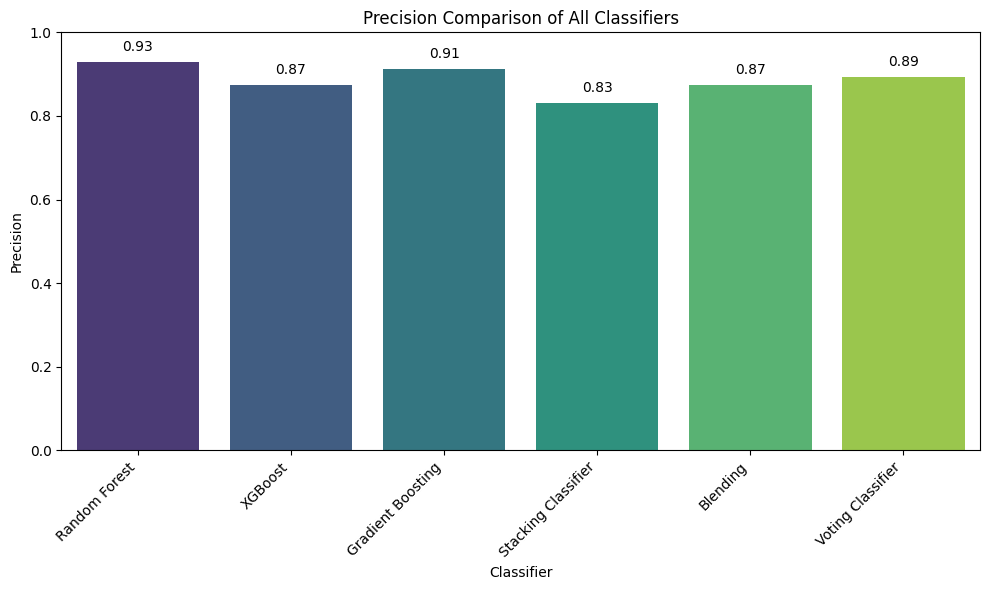

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_score


precisions = {
    "Random Forest": precision_score(y_test, y_pred_rf, average='weighted'),
    "XGBoost": precision_score(y_test, y_pred_xgb, average='weighted'),
    "Gradient Boosting": precision_score(y_test, y_pred_gb, average='weighted'),
    "Stacking Classifier": precision_score(y_test, y_pred_stacking, average='weighted'),
    "Blending": precision_score(y_test, blended_preds_final, average='weighted'),
    "Voting Classifier": precision_score(y_test, y_pred_voting, average='weighted')
}


plt.figure(figsize=(10, 6))
sns.barplot(x=list(precisions.keys()), y=list(precisions.values()), palette="viridis")
plt.title("Precision Comparison of All Classifiers")
plt.xlabel("Classifier")
plt.ylabel("Precision")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha='right')


for i, v in enumerate(precisions.values()):
    plt.text(i, v + 0.02, f"{v:.2f}", ha='center', va='bottom')

plt.tight_layout()
plt.show()

/tmp/ipykernel_3646/3589623551.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(recalls.keys()), y=list(recalls.values()), palette="viridis")


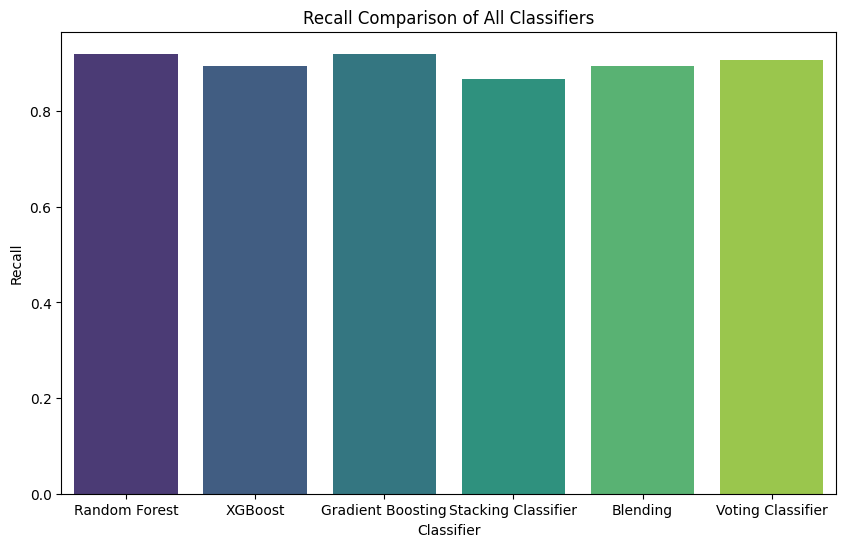

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import recall_score

recalls = {
    "Random Forest": recall_score(y_test, y_pred_rf, average='weighted'),
    "XGBoost": recall_score(y_test, y_pred_xgb, average='weighted'),
    "Gradient Boosting": recall_score(y_test, y_pred_gb, average='weighted'),
    "Stacking Classifier": recall_score(y_test, y_pred_stacking, average='weighted'),
    "Blending": recall_score(y_test, blended_preds_final, average='weighted'),
    "Voting Classifier": recall_score(y_test, y_pred_voting, average='weighted')
}

plt.figure(figsize=(10, 6))
sns.barplot(x=list(recalls.keys()), y=list(recalls.values()), palette="viridis")
plt.title("Recall Comparison of All Classifiers")
plt.xlabel("Classifier")
plt.ylabel("Recall")
plt.show()

In [ ]:
!pip install gradio

In [ ]:
import gradio as gr
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder

# Prediction function (unchanged)
def predict_dementia(visit, mr_delay, mf, hand, age, educ, ses, mmse, cdr, etiv, nwbv, asf):
    input_data = {
        "Visit": visit,
        "MR Delay": mr_delay,
        "M/F": mf,
        "Hand": hand,
        "Age": age,
        "EDUC": educ,
        "SES": ses,
        "MMSE": mmse,
        "CDR": cdr,
        "eTIV": etiv,
        "nWBV": nwbv,
        "ASF": asf
    }
    input_df = pd.DataFrame([input_data])
    input_df["M/F"] = label_encoders["M/F"].transform(input_df["M/F"])
    input_df["Hand"] = label_encoders["Hand"].transform(input_df["Hand"])
    prediction = rf.predict(input_df)
    group_mapping = {0: "Converted", 1: "Demented", 2: "Nondemented"}
    predicted_group = group_mapping[prediction[0]]
    return f"Predicted Group: {predicted_group}"


interface = gr.Interface(
    fn=predict_dementia,
    inputs=[
        gr.Number(label="Visit (1 or 2)", step=1, minimum=1, maximum=2),
        gr.Number(label="MR Delay (days)", minimum=0),
        gr.Dropdown(label="M/F", choices=["M", "F"]),
        gr.Dropdown(label="Hand", choices=["R", "L"]),
        gr.Number(label="Age (years)", minimum=0),
        gr.Number(label="EDUC (years of education)", minimum=0),
        gr.Number(label="SES (Socioeconomic Status, 1-5)", minimum=1, maximum=5),
        gr.Number(label="MMSE (Mini-Mental State Examination, 0-30)", minimum=0, maximum=30),
        gr.Number(label="CDR (Clinical Dementia Rating)", minimum=0, maximum=2, step=0.5),
        gr.Number(label="eTIV (Estimated Total Intracranial Volume)", minimum=0),
        gr.Number(label="nWBV (Normalized Whole Brain Volume)", minimum=0, maximum=1),
        gr.Number(label="ASF (Atlas Scaling Factor)", minimum=0)
    ],
    outputs=gr.Textbox(label="Prediction"),
    title="Dementia Prediction Using Random Forest",
    description="Enter the patient details to predict whether they are Converted, Demented, or Nondemented."
)

# Launch the interface
interface.launch(debug=True)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://2b3478f6fe15fcdc29.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
